<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab2_edge_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'input.jpg' not found locally. Downloading a sample image...


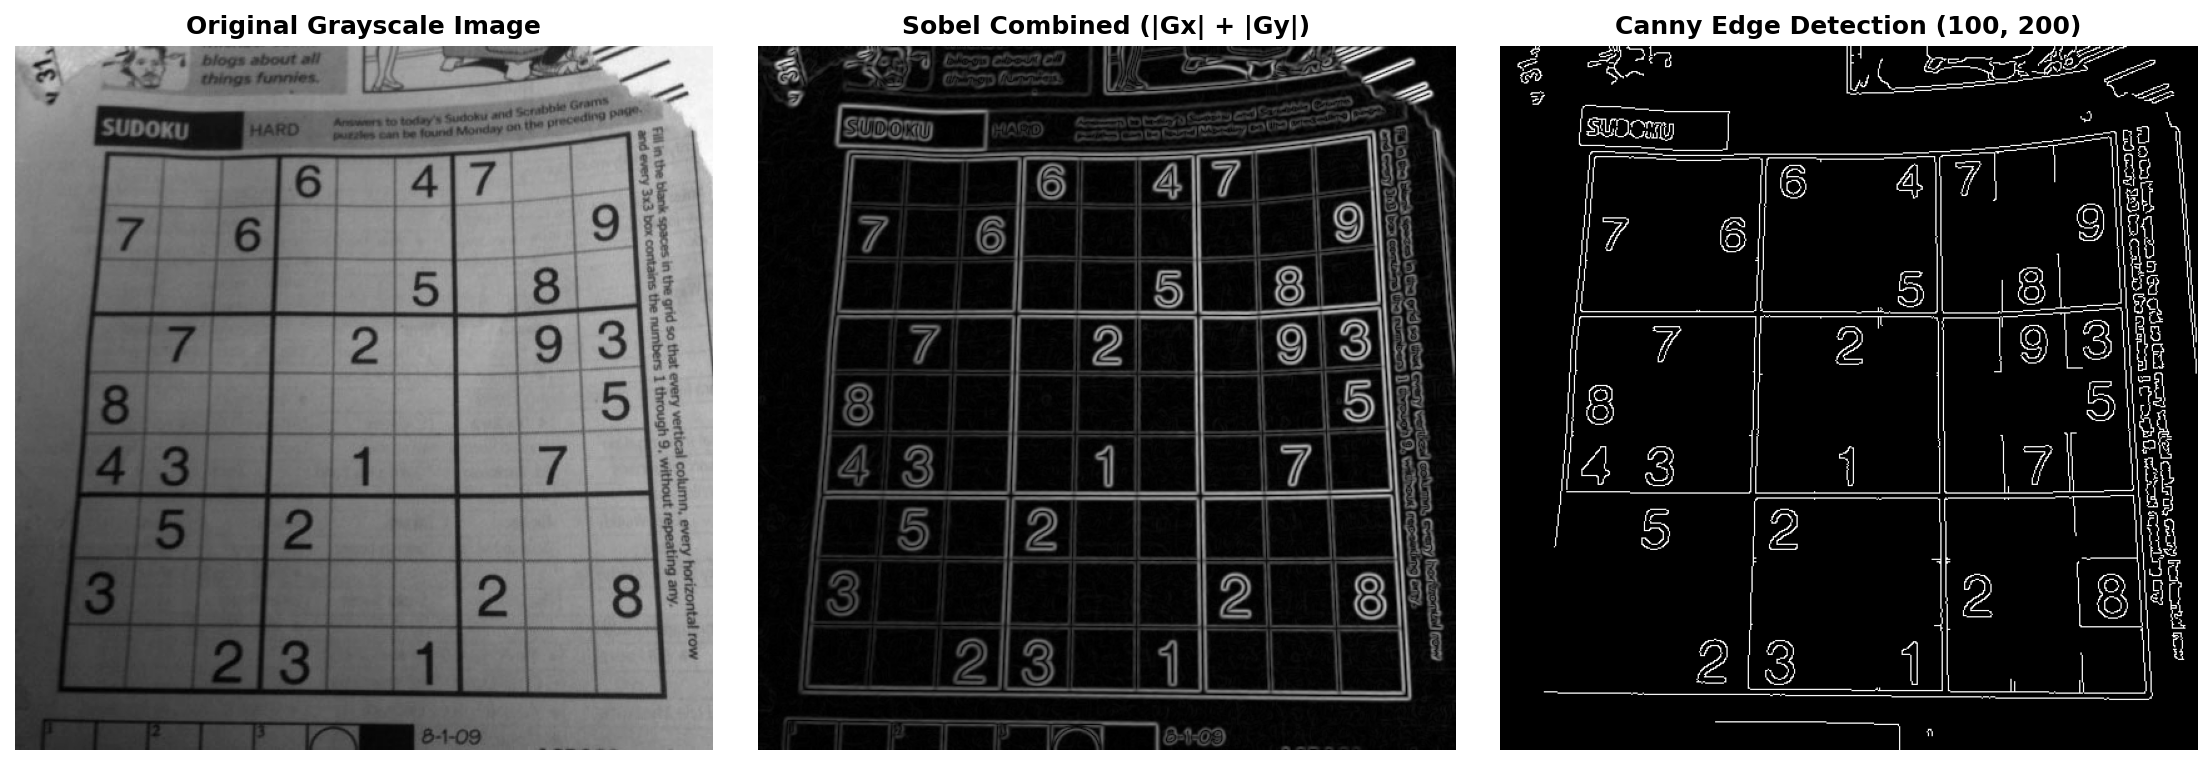

Execution complete. Artifacts saved: output_edge_comparison.png, output_sobel.png, output_canny.png


In [1]:
# ==========================================================
# CSST106 - Laboratory Exercise 3: Edge Detection Techniques
# Google Colab Compatible Script
# ==========================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

def run_edge_detection(image_path="input.jpg"):
    # Fallback: Download a high-detail sample if local image is missing
    if not os.path.exists(image_path):
        print(f"'{image_path}' not found locally. Downloading a sample image...")
        sample_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png"
        urllib.request.urlretrieve(sample_url, image_path)

    # 1. Load the input image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Failed to load image from {image_path}")

    # 2. Preprocessing: Gaussian Blur to suppress high-frequency noise
    # Kernel size (3, 3) prevents false edges from sensor grain/noise
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)

    # 3. Sobel Edge Detection (First-order derivative / Gradients)
    # cv2.CV_64F is used to capture negative gradient transitions without underflowing uint8
    sobel_x = cv2.Sobel(img_blur, cv2.CV_64F, 1, 0, ksize=3)  # Vertical edges
    sobel_y = cv2.Sobel(img_blur, cv2.CV_64F, 0, 1, ksize=3)  # Horizontal edges

    # Compute gradient magnitude: G = sqrt(Gx^2 + Gy^2)
    sobel_combined = cv2.magnitude(sobel_x, sobel_y)

    # Normalize/convert Sobel output to 8-bit unsigned integer (0-255) for saving
    sobel_8u = cv2.convertScaleAbs(sobel_combined)

    # 4. Canny Edge Detection (Multi-stage algorithm)
    # Thresholds: 100 (lower hysteresis bound), 200 (upper hysteresis bound)
    edges_canny = cv2.Canny(img_blur, 100, 200)

    # 5. Side-by-Side Visualization using Matplotlib
    plt.figure(figsize=(15, 5), dpi=150)

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Grayscale Image', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(sobel_combined, cmap='gray')
    plt.title('Sobel Combined (|Gx| + |Gy|)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(edges_canny, cmap='gray')
    plt.title('Canny Edge Detection (100, 200)', fontsize=12, fontweight='bold')
    plt.axis('off')

    plt.tight_layout()
    plt.savefig('output_edge_comparison.png', bbox_inches='tight')
    plt.show()

    # Save individual artifacts to Colab environment for report figures
    cv2.imwrite("output_original_gray.png", img)
    cv2.imwrite("output_sobel.png", sobel_8u)
    cv2.imwrite("output_canny.png", edges_canny)
    print("Execution complete. Artifacts saved: output_edge_comparison.png, output_sobel.png, output_canny.png")

if __name__ == "__main__":
    run_edge_detection('input.jpg')